# Test Both Models (GoogLeNet & YOLOv8)
A simple, straightforward example showing how to run inference with both models on an MRI image.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from ultralytics import YOLO

# 1. Resolve paths
MODELS_DIR = Path("../models") if Path("../models").exists() else Path("models")
DATA_DIR = Path("../data") if Path("../data").exists() else Path("data")

# 2. Load models
classifier = tf.keras.models.load_model(str(MODELS_DIR / "googlenet_brain_tumor.keras"))
detector = YOLO(str(MODELS_DIR / "yolov8_brain_tumor.pt"))

class_names = ["glioma", "meningioma", "notumor", "pituitary"]
print("Both models loaded successfully!")

Both models loaded successfully!


### 1. Select a Sample Image

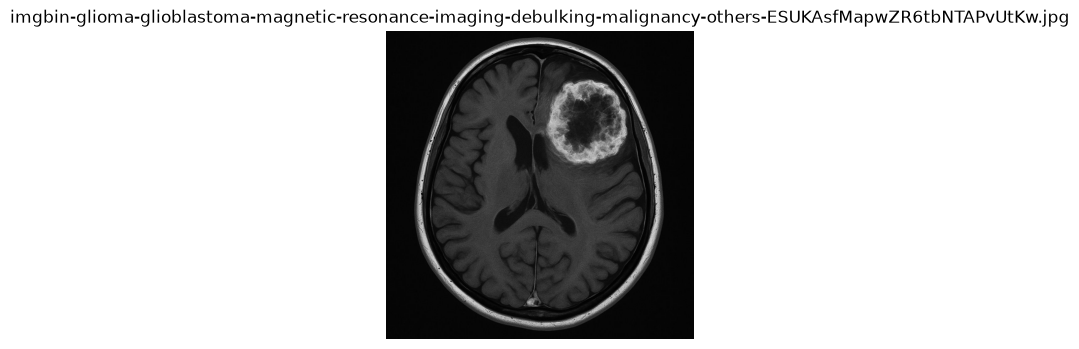

In [20]:
# Path to sample image
image_path = str(Path(r"C:\Users\anas\Desktop\Nouveau dossier\imgbin-glioma-glioblastoma-magnetic-resonance-imaging-debulking-malignancy-others-ESUKAsfMapwZR6tbNTAPvUtKw.jpg"))

# Read and display
img_bgr = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(4, 4))
plt.imshow(img_rgb)
plt.title(Path(image_path).name)
plt.axis("off")
plt.show()

### 2. Test Model 1: GoogLeNet (Classification)

In [21]:
# Preprocess (resize to 224x224, scale 0 to 1)
resized = cv2.resize(img_rgb, (224, 224)).astype(np.float32) / 255.0
batch = np.expand_dims(resized, axis=0)

# Predict class
probs = classifier.predict(batch, verbose=0)[0]
pred_class = class_names[np.argmax(probs)]
confidence = np.max(probs) * 100

print(f"Diagnosis: {pred_class} ({confidence:.2f}%)\n")
print("Probabilities by class:")
for name, prob in zip(class_names, probs):
    print(f"  - {name}: {prob*100:.2f}%")

Diagnosis: meningioma (89.16%)

Probabilities by class:
  - glioma: 0.02%
  - meningioma: 89.16%
  - notumor: 10.82%
  - pituitary: 0.00%


### 3. Test Model 2: YOLOv8 (Tumor Detection)

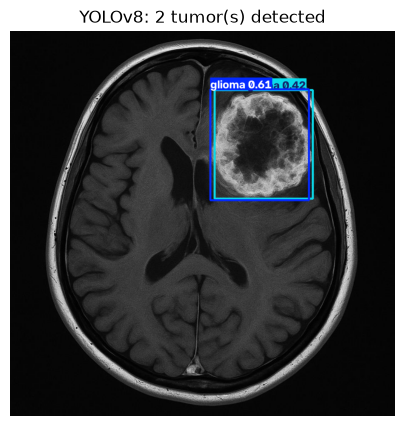

Box 1: glioma (60.9%) -> [520.4, 151.3, 776.4, 439.2]
Box 2: meningioma (41.7%) -> [531.5, 153.2, 786.1, 435.5]


In [22]:
# Run YOLO detection
results = detector.predict(image_path, conf=0.25, verbose=False)[0]

# Display image with bounding boxes
annotated = cv2.cvtColor(results.plot(), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(annotated)
plt.title(f"YOLOv8: {len(results.boxes)} tumor(s) detected")
plt.axis("off")
plt.show()

# Print detected bounding boxes
for i, box in enumerate(results.boxes, 1):
    cls_name = detector.names[int(box.cls[0])]
    conf = float(box.conf[0]) * 100
    x1, y1, x2, y2 = [round(v, 1) for v in box.xyxy[0].tolist()]
    print(f"Box {i}: {cls_name} ({conf:.1f}%) -> [{x1}, {y1}, {x2}, {y2}]")

### 4. Simple Helper: Test Any MRI Image with Both Models

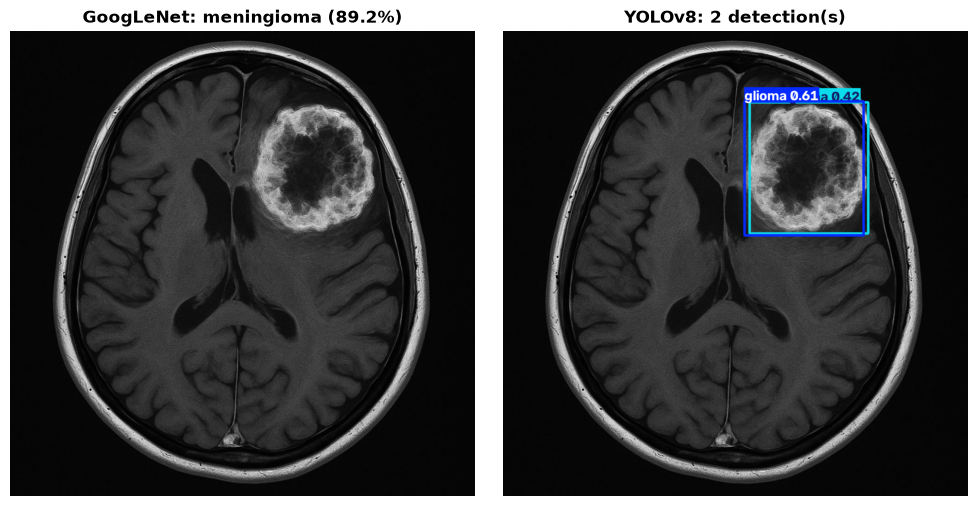

In [23]:
def test_mri(path):
    img = cv2.imread(str(path))
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # 1. Classification
    tensor = np.expand_dims(cv2.resize(rgb, (224, 224)).astype(np.float32) / 255.0, axis=0)
    probs = classifier.predict(tensor, verbose=0)[0]
    cls_name = class_names[np.argmax(probs)]
    cls_conf = np.max(probs) * 100
    
    # 2. Detection
    yolo_res = detector.predict(str(path), conf=0.25, verbose=False)[0]
    annotated = cv2.cvtColor(yolo_res.plot(), cv2.COLOR_BGR2RGB)
    
    # 3. Plot side by side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(rgb)
    ax1.set_title(f"GoogLeNet: {cls_name} ({cls_conf:.1f}%)", fontsize=12, fontweight="bold")
    ax1.axis("off")
    
    ax2.imshow(annotated)
    ax2.set_title(f"YOLOv8: {len(yolo_res.boxes)} detection(s)", fontsize=12, fontweight="bold")
    ax2.axis("off")
    
    plt.tight_layout()
    plt.show()

# Test on another scan (e.g. Meningioma)
test_mri(image_path)